# Stage 4 — Do the conclusions hold beyond one circuit?

Stages 1–3 used a single feature map (ZZ re-uploading). Stage 4 repeats the decisive tests on **ten circuit families**, so the paper's claims are about projected quantum kernels rather than about one circuit:

| Class | Families |
|---|---|
| Commuting entanglers (two-qubit gates commute with each other) | `zz_reupload` (Stages 1–3), `havlicek_zz`, `iqp`, `cz_layers`, `ms_xx` |
| Non-commuting entanglers | `xy`, `heisenberg`, `hea_cnot`, `crx` |
| Product-state control | `separable` |

A qubit's **light cone** is measured from each circuit itself (which inputs actually change that qubit's state), because for non-commuting gates it is no longer the graph-distance cone; a CNOT ladder, for example, carries information along a whole chain within one layer.

**Frozen hypotheses** (`stage4_frozen.json`)
* **Part A, concentration.** A1: per-qubit concentration is governed by coupling degree in every family (Stage 2 C2). A2: at equal degree, the light cone does not matter (Stage 2 C3).
* **Part B, task performance** (3 binary tasks, 8 qubits). B1: concentration does not predict accuracy. B2: removing the two-qubit gates costs no meaningful accuracy. B3: non-inferior to RBF-SVM. B4: bandwidth matters more than graph.

| Section | Content | Checkpoint |
|---|---|---|
| 1 | Configuration, freeze, module and code-hash verification | All verified |
| 2 | Data: Part A inputs, Part B views and fixed subsets | Sizes printed |
| 3 | Circuit verification (every family against an independent dense implementation) | All `PASS` |
| 4 | Part A: light cones and per-qubit concentration | Cone checks `PASS`, results CSV |
| 5 | Part A hypotheses A1–A3 | Part A verdict printed |
| 6 | Part B: projected kernels for all families and classical comparators | Results CSV, 0 failed fits |
| 7 | Part B hypotheses B1–B4, reproduction of Stage 3, overall verdict | Verdict printed |
| 8 | Figures | Saved |

Run `MODE = "smoke"` first (synthetic data, about 5–10 minutes), then freeze, then `MODE = "run"`. Edit nothing but the MODE line.

## 1. Configuration and freeze verification

In [9]:
from pathlib import Path
import os, sys, json, hashlib, time, itertools, warnings
import numpy as np, pandas as pd
warnings.filterwarnings("ignore")

MODE = "run"#"smoke"             # "smoke" -> synthetic data, small grid | "run" -> the frozen Stage 4 experiment
ROOT = Path(os.environ.get("PQK_ROOT", Path.cwd() / "pqk-nids"))
HERE = Path(os.environ.get("PQK_CODE_DIR", Path.cwd()))          # folder with this notebook and pqk_circuits.py
NOTEBOOK, MODULE = HERE / "stage4_generalisation.ipynb", HERE / "pqk_circuits.py"
N_JOBS = int(os.environ.get("PQK_N_JOBS", max(1, (os.cpu_count() or 2) - 1)))
PHASE0_MODE = "quick"; GLOBAL_SEED = 20261001
REDUCED = os.environ.get("PQK_S4_REDUCED") == "1"     # developer test switch: a reduced grid is NEVER a valid result
RES = ROOT / "results" / "stage4" / (MODE + ("_REDUCED_INVALID" if REDUCED else ""))
RA, RB = RES / "partA", RES / "partB"
for d in [RES, RA, RB]: d.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(HERE)); import pqk_circuits as pc
os.environ["PYTHONPATH"] = str(HERE) + os.pathsep + os.environ.get("PYTHONPATH", "")   # parallel workers import the same module

def sha(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for b in iter(lambda: f.read(1 << 20), b""): h.update(b)
    return h.hexdigest()
def code_hash(path):
    nb = json.loads(Path(path).read_text()); src = []
    for c in nb["cells"]:
        if c["cell_type"] == "code":
            s = "".join(c["source"]) if isinstance(c["source"], list) else c["source"]
            src.append("\n".join(l for l in s.splitlines() if not l.strip().startswith("MODE =")))
    return hashlib.sha256("\n#----\n".join(src).encode()).hexdigest()

if MODE == "run":
    F4 = ROOT / "stage4_freeze" / "stage4_frozen.json"; assert F4.exists(), "No Stage 4 freeze. Run freeze_stage4.py first."
    t4 = F4.read_text(); assert hashlib.sha256(t4.encode()).hexdigest() == (F4.parent / "stage4_frozen.json.sha256").read_text().split()[0], "Stage 4 freeze modified"
    FZ4 = json.loads(t4)
    for key, rel in [("phase1_freeze_sha256", "phase1_freeze/phase1_frozen_inputs.json"), ("phase1b_freeze_sha256", "phase1b_freeze/phase1b_frozen.json"),
                     ("phase2_freeze_sha256", "phase2_freeze/phase2_frozen.json")]:
        assert hashlib.sha256((ROOT / rel).read_text().encode()).hexdigest() == FZ4["builds_on"][key], f"{rel} differs from the freeze Stage 4 builds on"
    FZ1 = json.loads((ROOT / "phase1_freeze" / "phase1_frozen_inputs.json").read_text())
    bad = [k for k, v in FZ1["file_sha256"].items() if sha(ROOT / k) != v]; assert not bad, f"Inputs changed since the Phase 1 freeze: {bad}"
    assert sha(MODULE) == FZ4["module_sha256"], "pqk_circuits.py differs from the frozen module"
    assert NOTEBOOK.exists(), f"Save this notebook as {NOTEBOOK} (or set PQK_CODE_DIR)"
    assert code_hash(NOTEBOOK) == FZ4["notebook_code_sha256"], "Notebook code differs from the frozen code (only MODE may change). Save and re-check."
    A_, B_ = FZ4["partA"], FZ4["partB"]
    QA, LA, CA, NSAMP, GA = A_["qubits"], A_["layers"], A_["bandwidths"], A_["samples_per_config"], A_["graphs"]
    TASKS, NS, SEEDS, GB, LB, CB = B_["tasks"], B_["training_sizes"], B_["seeds"], B_["graphs"], B_["layers"], B_["bandwidths"]
    print(f"Stage 4 freeze verified (created {FZ4['created']}); earlier freezes and inputs unchanged; module and notebook code match.")
else:
    FZ1 = FZ4 = None
    QA, LA, CA, NSAMP = [8], [1, 2], [0.6], 40
    GA = ["empty", "matching", "chain", "ring", "cycles4", "k4s", "regular3", "star"]
    TASKS, NS, SEEDS, GB, LB, CB = {"synthetic:binary": "raw8"}, [250], [0, 1], ["empty", "ring", "star"], [1], [0.6]
if REDUCED:
    QA, LA, CA = [8], [1, 2], [0.6]
    NS, SEEDS, GB, LB, CB = [250, 1000], [0, 1], ["empty", "ring", "star"], [1], [0.6, 1.0]
    print("WARNING: REDUCED developer grid. These results are not valid and must not be reported.")
FAMS, ENT = pc.FAMILIES, pc.ENTANGLING
GAMMA_MULT, C_GRID = [0.5, 1.0, 2.0], [1, 10, 100]
VAL_SIZE, TEST_SIZE = 2000, 4000
print(f"MODE={MODE}  families={len(FAMS)}  N_JOBS={N_JOBS}")
print(f"Part A: qubits={QA} L={LA} c={CA} samples={NSAMP} graphs={len(GA)}")
print(f"Part B: tasks={list(TASKS)} N={NS} seeds={SEEDS} graphs={GB} L={LB} c={CB}")
print("CHECKPOINT 1: configuration ready.")

Stage 4 freeze verified (created 2026-10-07 09:59:53 EDT); earlier freezes and inputs unchanged; module and notebook code match.
MODE=run  families=10  N_JOBS=15
Part A: qubits=[8, 12] L=[1, 2, 3] c=[0.3, 0.6, 1.0] samples=200 graphs=15
Part B: tasks=['fashion_mnist:binary', 'nf_unsw_nb15_v2:binary', 'unsw_nb15:binary'] N=[250, 1000, 4000] seeds=[0, 1, 2] graphs=['empty', 'chain', 'ring', 'star', 'regular3', 'complete'] L=[1, 2] c=[0.3, 0.6, 1.0]
CHECKPOINT 1: configuration ready.


## 2. Data
**Part A** uses 200 fresh training rows per dataset (none used in Stages 1–2) plus Gaussian inputs, with up to 12 features (PCA-16 for Fashion-MNIST, MI-16 for the two security datasets, first *n* columns). **Part B** uses exactly the Stage 3 views (PCA-8, MI-8), validation and test subsets and training samples, so the `zz_reupload` rows reproduce Stage 3.

In [10]:
import joblib, networkx as nx
def signed_log1p(X):   # needed to unpickle the Phase 0 preprocessors
    return np.sign(X) * np.log1p(np.abs(X))
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.kernel_approximation import RBFSampler
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.utils.class_weight import compute_sample_weight
import xgboost as xgb, lightgbm as lgb

def grid(model, d):
    if model == "lr":   return [dict(C=c) for c in [0.1, 1, 10]]
    if model == "svm":  return [dict(C=c, gm=g) for c in [1, 10] for g in [0.3, 1, 3]]
    if model == "rff":  return [dict(C=c, gm=g) for c in [1, 10] for g in [0.3, 1, 3]]
    if model == "rf":   return [dict(max_depth=m) for m in [None, 20]]
    if model == "xgb":  return [dict(max_depth=m) for m in [6, 10]]
    if model == "lgbm": return [dict(num_leaves=n) for n in [31, 127]]
    if model == "mlp":  return [dict(alpha=a) for a in [1e-4, 1e-3]]

def build(model, hp, seed, Xtr, ytr):
    g0 = 1.0 / (Xtr.shape[1] * max(float(Xtr.var()), 1e-12))
    if model == "lr":   return LogisticRegression(C=hp["C"], class_weight="balanced", max_iter=3000), None
    if model == "svm":  return SVC(C=hp["C"], gamma=hp["gm"] * g0, class_weight="balanced", random_state=seed), None
    if model == "rff":  return Pipeline([("rff", RBFSampler(gamma=hp["gm"] * g0, n_components=1000, random_state=seed)),
                                          ("lr", LogisticRegression(C=hp["C"], class_weight="balanced", max_iter=3000))]), None
    if model == "rf":   return RandomForestClassifier(n_estimators=300, max_depth=hp["max_depth"], class_weight="balanced", n_jobs=1, random_state=seed), None
    if model == "xgb":  return xgb.XGBClassifier(n_estimators=400, max_depth=hp["max_depth"], learning_rate=0.1, tree_method="hist",
                                                 n_jobs=1, random_state=seed), compute_sample_weight("balanced", ytr)
    if model == "lgbm": return lgb.LGBMClassifier(n_estimators=400, num_leaves=hp["num_leaves"], learning_rate=0.05, class_weight="balanced",
                                                  n_jobs=1, random_state=seed, verbose=-1), None
    if model == "mlp":  return MLPClassifier(hidden_layer_sizes=(128, 64), alpha=hp["alpha"], early_stopping=True, max_iter=300, random_state=seed), None

def sample_n(y, n, seed, min_per_class=2):
    # proportional stratified sample of size ~n with at least `min_per_class` per class present (identical to Stage 3)
    rng = np.random.default_rng(seed); cls, cnt = np.unique(y, return_counts=True)
    if n >= len(y): return rng.permutation(len(y))
    take = np.maximum(np.minimum(cnt, min_per_class), np.round(n * cnt / cnt.sum()).astype(int)); take = np.minimum(take, cnt)
    idx = np.concatenate([rng.choice(np.flatnonzero(y == c), t, replace=False) for c, t in zip(cls, take)])
    return rng.permutation(idx)

# ---------------- Part A inputs
NMAX = max(QA)
INPUTS = {"gaussian": np.random.default_rng(GLOBAL_SEED + 4).standard_normal((NSAMP, NMAX))}
OVERLAP = {}
DATA = {}
if MODE == "run":
    PROC = ROOT / "data" / "processed"; ranks = json.load(open(ROOT / "results" / "phase0" / PHASE0_MODE / "feature_rankings.json"))
    def fresh_rows(ds):
        tr = pd.read_parquet(PROC / ds / f"train_{PHASE0_MODE}.parquet"); allr = np.arange(len(tr))
        used1 = np.sort(np.random.default_rng(GLOBAL_SEED).choice(len(tr), 200, replace=False))                 # Stage 1 rows
        pool1 = np.setdiff1d(allr, used1)
        used2 = np.sort(np.random.default_rng(GLOBAL_SEED + 1).choice(pool1, 200, replace=False))              # Stage 2 rows
        pool2 = np.setdiff1d(pool1, used2)
        idx = np.sort(np.random.default_rng(GLOBAL_SEED + 4).choice(pool2, NSAMP, replace=False))
        OVERLAP[ds] = int(np.intersect1d(idx, np.union1d(used1, used2)).size)
        return tr.iloc[idx]
    tr = fresh_rows("fashion_mnist"); pre = joblib.load(PROC / "fashion_mnist" / f"preprocessor_{PHASE0_MODE}.joblib")
    pca, sc = joblib.load(PROC / "fashion_mnist" / f"pca_{PHASE0_MODE}.joblib")[16]
    INPUTS["fashion_mnist"] = sc.transform(pca.transform(pre["ct"].transform(tr[pre["cols"]])))[:, :NMAX]
    for ds in ["nf_unsw_nb15_v2", "unsw_nb15"]:
        tr = fresh_rows(ds); pre = joblib.load(PROC / ds / f"preprocessor_{PHASE0_MODE}.joblib")
        X = pre["ct"].transform(tr[pre["cols"]]); names = list(pre["names"])
        assert ranks[ds]["mi"][:16] == FZ1["feature_definitions"][f"{ds}/mi16"], "MI-16 list differs from the Phase 1 freeze"
        INPUTS[ds] = np.asarray(X[:, [names.index(f) for f in ranks[ds]["mi"][:16]]], dtype=float)[:, :NMAX]
    assert all(v == 0 for v in OVERLAP.values()), f"Part A rows overlap Stage 1-2 rows: {OVERLAP}"

    # ---------------- Part B views (identical to Stage 3)
    for task, view in TASKS.items():
        ds = task.split(":")[0]; pre = joblib.load(PROC / ds / f"preprocessor_{PHASE0_MODE}.joblib"); out = {}
        for split in ["train", "val", "test"]:
            fr = pd.read_parquet(PROC / ds / f"{split}_{PHASE0_MODE}.parquet"); M = pre["ct"].transform(fr[pre["cols"]])
            if view == "pca8":
                pca, sc = joblib.load(PROC / ds / f"pca_{PHASE0_MODE}.joblib")[8]; X = sc.transform(pca.transform(M))
            else:
                names = list(pre["names"]); feats = ranks[ds]["mi"][:8]
                assert feats == FZ1["feature_definitions"][f"{ds}/mi8"], "MI-8 list differs from the freeze"
                X = np.asarray(M[:, [names.index(f) for f in feats]])
            out[split] = (np.asarray(X, dtype=np.float64), fr["y_bin"].to_numpy().astype(int))
        DATA[task] = out
else:
    rng = np.random.default_rng(0); out = {}
    for split, n in [("train", 3000), ("val", 600), ("test", 600)]:
        X = rng.standard_normal((n, 8)); y = ((X[:, 0] * X[:, 1] + 0.7 * X[:, 2] + 0.3 * rng.standard_normal(n)) > 0).astype(int)
        out[split] = (X, y)
    DATA["synthetic:binary"] = out
INPUTS = {k: np.asarray(v, dtype=np.float64) for k, v in INPUTS.items()}   # simulate in float64
for k, v in INPUTS.items():
    print(f"Part A {k:18s} shape={v.shape}  mean={v.mean():+.3f}  sd={v.std():.3f}" + (f"  rows shared with Stages 1-2: {OVERLAP[k]}" if k in OVERLAP else ""))

SUB = {}
for task, d in DATA.items():
    iv = sample_n(d["val"][1], VAL_SIZE, 0); it = sample_n(d["test"][1], TEST_SIZE, GLOBAL_SEED)
    tr_idx = {(N, s): sample_n(d["train"][1], min(N, len(d["train"][1])), s) for N in NS for s in SEEDS}
    SUB[task] = dict(val=iv, test=it, train=tr_idx)
    print(f"Part B {task:26s} train pool={len(d['train'][1]):>7,}  val subset={len(iv):,}  test subset={len(it):,}  "
          f"test positive share={d['test'][1][it].mean():.3f}")
print("CHECKPOINT 2: data and fixed subsets ready.")

Part A gaussian           shape=(200, 12)  mean=-0.014  sd=0.990
Part A fashion_mnist      shape=(200, 12)  mean=+0.002  sd=1.000  rows shared with Stages 1-2: 0
Part A nf_unsw_nb15_v2    shape=(200, 12)  mean=-0.019  sd=0.958  rows shared with Stages 1-2: 0
Part A unsw_nb15          shape=(200, 12)  mean=-0.009  sd=0.979  rows shared with Stages 1-2: 0
Part B fashion_mnist:binary       train pool=  9,600  val subset=2,000  test subset=2,000  test positive share=0.500
Part B nf_unsw_nb15_v2:binary     train pool= 62,412  val subset=2,000  test subset=4,000  test positive share=0.337
Part B unsw_nb15:binary           train pool= 80,648  val subset=2,000  test subset=4,000  test positive share=0.360
CHECKPOINT 2: data and fixed subsets ready.


## 3. Circuit verification
Every family is checked against an **independent dense implementation** (full 2ⁿ×2ⁿ matrices built by explicit index mapping, Bloch vectors from explicit partial traces). `zz_reupload` must reproduce the Stage 1–3 simulator and the single-layer closed form. All must pass, otherwise nothing is interpreted.

In [11]:
def zsigns(n):
    D = 2 ** n; bits = (np.arange(D)[:, None] >> (n - 1 - np.arange(n))) & 1
    return 1 - 2 * bits
def simulate_stage13(X, edges, L, c):        # the Stage 1-3 simulator, unchanged
    N, n = X.shape; D = 2 ** n
    psi = np.zeros((N, D), dtype=complex); psi[:, 0] = 1.0
    if edges:
        s = zsigns(n); S = np.stack([s[:, i] * s[:, j] for i, j in edges], 1)
        W = np.stack([X[:, i] * X[:, j] for i, j in edges], 1)
        phase = np.exp(-0.5j * (c ** 2) * (W @ S.T))
    for _ in range(L):
        for k in range(n):
            th = c * X[:, k]; co = np.cos(th / 2)[:, None, None]; si = np.sin(th / 2)[:, None, None]
            p = psi.reshape(N, 2 ** k, 2, 2 ** (n - k - 1))
            a0 = p[:, :, 0, :].copy(); a1 = p[:, :, 1, :].copy()
            p[:, :, 0, :] = co * a0 - si * a1
            p[:, :, 1, :] = si * a0 + co * a1
        if edges:
            psi = psi * phase
    return psi
def closed_form_L1(X, edges, c):
    n = X.shape[1]; nb = {k: [] for k in range(n)}; R = np.empty((X.shape[0], n, 3))
    for i, j in edges: nb[i].append(j); nb[j].append(i)
    for k in range(n):
        t = c * X[:, k]; P = np.ones(X.shape[0], dtype=complex)
        for j in nb[k]:
            p = c ** 2 * X[:, k] * X[:, j]; P = P * (np.cos(p) + 1j * np.sin(p) * np.cos(c * X[:, j]))
        R[:, k] = np.stack([np.sin(t) * P.real, np.sin(t) * P.imag, np.cos(t)], 1)
    return R

def families(n, seed=GLOBAL_SEED):           # the Stage 2 graph generator, unchanged
    F = {"empty": [], "chain": [(i, i + 1) for i in range(n - 1)], "ring": [(i, (i + 1) % n) for i in range(n)],
         "star": [(0, i) for i in range(1, n)], "complete": [(i, j) for i in range(n) for j in range(i + 1, n)],
         "wheel": [(0, i) for i in range(1, n)] + [(i, i % (n - 1) + 1) for i in range(1, n)]}
    h = n // 2
    F["double_star"] = [(0, 1)] + [(0, i) for i in range(2, h + 1)] + [(1, i) for i in range(h + 1, n)]
    if n % 2 == 0: F["matching"] = [(i, i + 1) for i in range(0, n, 2)]
    def cycles(sizes):
        e, s0 = [], 0
        for m in sizes:
            e += [(s0 + i, s0 + (i + 1) % m) for i in range(m)]; s0 += m
        return e
    if n % 4 == 0: F["cycles4"] = cycles([4] * (n // 4))
    if n % 3 == 0: F["triangles"] = cycles([3] * (n // 3))
    F["two_cycles"] = cycles([n // 2, n - n // 2])
    if n % 4 == 0: F["k4s"] = sum(([(b + i, b + j) for i in range(4) for j in range(i + 1, 4)] for b in range(0, n, 4)), [])
    if n % 2 == 0:
        for s in range(seed, seed + 500):
            g = nx.random_regular_graph(3, n, seed=s)
            if nx.is_connected(g): F["regular3"] = sorted(tuple(sorted(e)) for e in g.edges()); break
    for tag, off in [("a", 0), ("b", 1000)]:
        for s in range(seed + off, seed + off + 500):
            g = nx.gnp_random_graph(n, 0.3, seed=s)
            if nx.is_connected(g): F[f"erdos_renyi_{tag}"] = sorted(tuple(sorted(e)) for e in g.edges()); break
        r = np.random.default_rng(seed + off + n)
        g = nx.from_prufer_sequence(list(r.integers(0, n, n - 2)))
        F[f"random_tree_{tag}"] = sorted(tuple(sorted(e)) for e in g.edges())
    out, seen = {}, set()
    for k, E in F.items():
        key = frozenset(tuple(sorted(e)) for e in E)
        if key not in seen: seen.add(key); out[k] = [tuple(sorted(e)) for e in E]
    return out

CHECKS = {}
rng = np.random.default_rng(3); n4 = 4; E4 = [(0, 1), (1, 2), (2, 3), (0, 3), (1, 3)]
w = 0.0
for f in FAMS:
    X = rng.standard_normal((2, n4))
    for c in [0.4, 1.1]:
        g = pc.build_circuit(f, X, E4, 2, c); psi = pc.simulate(g, 2, n4); R = pc.bloch(psi, n4)
        for i in range(2):
            w = max(w, np.abs(psi[i] - pc.dense_state(g, n4, i)).max(), np.abs(R[i] - pc.dense_bloch(psi[i], n4)).max())
CHECKS["V1_dense_all_families_n4_L2"] = dict(max_abs_diff=float(w), pass_=bool(w < 1e-12))
w = 0.0
for name in ["zz", "xx", "xy", "heis", "crx", "cnot", "cz"]:
    for q in [(2, 0), (3, 1), (0, 2), (1, 3)]:
        tt = None if name in ("cnot", "cz") else rng.standard_normal(2)
        g = [(1, "ry", (k,), rng.standard_normal(2)) for k in range(n4)] + [(1, "rz", (k,), rng.standard_normal(2)) for k in range(n4)] + [(2, name, q, tt)]
        psi = pc.simulate(g, 2, n4); w = max(w, max(np.abs(psi[i] - pc.dense_state(g, n4, i)).max() for i in range(2)))
CHECKS["V2_two_qubit_gates_any_qubit_order"] = dict(max_abs_diff=float(w), pass_=bool(w < 1e-12))
from scipy.linalg import expm
Xp, Yp, Zp = np.array([[0, 1], [1, 0]]), np.array([[0, -1j], [1j, 0]]), np.diag([1, -1])
gens = {"zz": np.kron(Zp, Zp), "xx": np.kron(Xp, Xp), "xy": np.kron(Xp, Xp) + np.kron(Yp, Yp), "heis": np.kron(Xp, Xp) + np.kron(Yp, Yp) + np.kron(Zp, Zp)}
t = rng.standard_normal(4)
w = max(np.abs(pc._two(nm, t)[i] - expm(-0.5j * t[i] * G)).max() for nm, G in gens.items() for i in range(4))
CHECKS["V3_gates_equal_matrix_exponentials"] = dict(max_abs_diff=float(w), pass_=bool(w < 1e-12))
w = wc = 0.0
for nq in [8, 10]:
    for name, E in families(nq).items():
        X = rng.standard_normal((10, nq))
        for L in [1, 2, 3]:
            w = max(w, np.abs(pc.bloch(simulate_stage13(X, E, L, 0.7), nq) - pc.bloch_vectors("zz_reupload", X, E, L, 0.7)).max())
        wc = max(wc, np.abs(closed_form_L1(X, E, 0.7) - pc.bloch_vectors("zz_reupload", X, E, 1, 0.7)).max())
CHECKS["V4_zz_reupload_equals_stage1_3_simulator"] = dict(max_abs_diff=float(w), pass_=bool(w < 1e-12))
CHECKS["V5_zz_reupload_closed_form_L1"] = dict(max_abs_diff=float(wc), pass_=bool(wc < 1e-10))
E8 = families(8)["complete"]; X = rng.standard_normal((4, 8))
w = max(np.abs(np.linalg.norm(pc.simulate(pc.build_circuit(f, X, E8, 3, 1.0), 4, 8), axis=1) - 1).max() for f in FAMS)
CHECKS["V6_normalisation_n8_complete_L3"] = dict(max_norm_error=float(w), pass_=bool(w < 1e-12))
def show_checks(prefixes=None):
    for k, v in CHECKS.items():
        if prefixes and not k.startswith(prefixes): continue
        print(f"{'PASS' if v['pass_'] else 'FAIL'}  {k}  {({a: b for a, b in v.items() if a != 'pass_'})}")
show_checks(); json.dump(CHECKS, open(RES / "circuit_checks.json", "w"), indent=2)
assert all(v["pass_"] for v in CHECKS.values()), "Circuit checks failed: stop."
print("CHECKPOINT 3: all ten circuit families verified.")

PASS  V1_dense_all_families_n4_L2  {'max_abs_diff': 3.885780586188048e-16}
PASS  V2_two_qubit_gates_any_qubit_order  {'max_abs_diff': 2.482534153247273e-16}
PASS  V3_gates_equal_matrix_exponentials  {'max_abs_diff': 2.2887833992611187e-16}
PASS  V4_zz_reupload_equals_stage1_3_simulator  {'max_abs_diff': 1.7763568394002505e-15}
PASS  V5_zz_reupload_closed_form_L1  {'max_abs_diff': 1.1102230246251565e-15}
PASS  V6_normalisation_n8_complete_L3  {'max_norm_error': 3.1086244689504383e-15}
CHECKPOINT 3: all ten circuit families verified.


## 4. Part A: light cones and per-qubit concentration
For every family, graph, qubit count and depth, the **light cone** of each qubit is measured from the circuit (shift each input, see which qubits change). Three more checks: every cone lies inside the backward gate-walk bound; for `zz_reupload` it equals the graph-distance cone of Stages 1–2; and the threshold cleanly separates numerical zero from genuine (even very weak) dependence. Then V_k is computed for every configuration. Results are appended as they finish; re-running skips finished work.

In [12]:
from joblib import Parallel, delayed
GRAPHS_A = {n: {g: E for g, E in families(n).items() if g in GA} for n in QA}
for n in QA: print(f"n={n}: {len(GRAPHS_A[n])} graphs  {list(GRAPHS_A[n])}")
def degrees(E, n):
    d = np.zeros(n, int)
    for i, j in E: d[i] += 1; d[j] += 1
    return d
def graph_cone(n, E, L):
    g = nx.Graph(); g.add_nodes_from(range(n)); g.add_edges_from(E)
    return np.array([len(nx.single_source_shortest_path_length(g, k, cutoff=L)) for k in range(n)])
def fam_graphs(f, n):
    return ["empty"] if f == "separable" else list(GRAPHS_A[n])

def cone_job(f, n, g, L):
    E = GRAPHS_A[n][g]; dep, sens = pc.dependence_cones(f, n, E, L)
    return (f, n, g, L), dep, sens, pc.gate_walk_cones(f, n, E, L)
t0 = time.time()
cj = [(f, n, g, L) for f in FAMS for n in QA for g in fam_graphs(f, n) for L in LA]
cj.sort(key=lambda j: -(j[1] * 100 + len(GRAPHS_A[j[1]][j[2]]) * j[3]))
out = Parallel(n_jobs=N_JOBS)(delayed(cone_job)(*j) for j in cj)
CONES = {k: dep for k, dep, _, _ in out}
allsens = np.concatenate([s.ravel() for _, _, s, _ in out])
viol = int(sum(bool((dep & ~walk).any()) for _, dep, _, walk in out))
CHECKS["V7_cone_inside_gate_walk_bound"] = dict(settings=len(out), violations=viol, pass_=bool(viol == 0))
mism = sum(int(not np.array_equal(CONES[("zz_reupload", n, g, L)].sum(1), graph_cone(n, GRAPHS_A[n][g], L))) for n in QA for g in GRAPHS_A[n] for L in LA)
CHECKS["V8_zz_reupload_cone_equals_graph_cone"] = dict(mismatches=int(mism), pass_=bool(mism == 0))
band = int(((allsens >= 1e-14) & (allsens < 1e-12)).sum())
CHECKS["V9_cone_threshold_separates_zero_from_signal"] = dict(largest_numerical_zero=float(allsens[allsens < 1e-13].max()) if (allsens < 1e-13).any() else 0.0,
                                                           weakest_dependence=float(allsens[allsens >= 1e-13].min()), values_in_ambiguous_band=band, pass_=bool(band == 0))
show_checks(("V7", "V8", "V9")); json.dump(CHECKS, open(RES / "circuit_checks.json", "w"), indent=2)
assert all(v["pass_"] for v in CHECKS.values()), "Cone checks failed: stop."
crow = []
for (f, n, g, L), dep in CONES.items():
    E = GRAPHS_A[n][g]; deg = degrees(E, n) if f != "separable" else np.zeros(n, int); gc = graph_cone(n, E, L) if f != "separable" else np.ones(n, int)
    crow.append(dict(family=f, n=n, graph=g, L=L, edges=len(E) if f != "separable" else 0, deg_min=int(deg.min()), deg_max=int(deg.max()),
                     dep_cone_mean=float(dep.sum(1).mean()), graph_cone_mean=float(gc.mean()), dep_cone_per_qubit=" ".join(map(str, dep.sum(1)))))
CT = pd.DataFrame(crow); CT.to_csv(RA / "cones.csv", index=False)
print(f"cones for {len(CONES)} (family, n, graph, L) settings in {time.time() - t0:.0f}s")
show = CT[(CT.n == min(QA)) & (CT.L == max(LA)) & CT.graph.isin(["chain", "ring", "star", "k4s", "regular3"])]
print(show.pivot_table(index="graph", columns="family", values="dep_cone_mean").round(2).to_string())

def a_job(f, n, g, L, c):
    E = GRAPHS_A[n][g] if f != "separable" else []; srcs = list(INPUTS)
    X = np.vstack([INPUTS[s][:, :n] for s in srcs])
    R = pc.bloch_vectors(f, X, E, L, c, batch=400).reshape(len(srcs), NSAMP, n, 3)
    deg = degrees(E, n); cone = CONES[(f, n, g, L)].sum(1); gc = graph_cone(n, E, L); dens = len(E) / (n * (n - 1) / 2)
    return [dict(family=f, inputs=s, c=c, n=n, graph=g, L=L, k=k, degree=int(deg[k]), dep_cone=int(cone[k]), graph_cone=int(gc[k]),
                 density=dens, V=float(np.trace(np.cov(R[si, :, k].T)))) for si, s in enumerate(srcs) for k in range(n)]

OUTA = RA / "per_qubit.csv"; COLS_A = ["family", "inputs", "c", "n", "graph", "L", "k", "degree", "dep_cone", "graph_cone", "density", "V"]
doneA = set()
if OUTA.exists():
    prev = pd.read_csv(OUTA); assert list(prev.columns) == COLS_A, "per_qubit.csv has an old layout: delete it and rerun"
    doneA = set(zip(prev.family, prev.n, prev.graph, prev.L, prev.c))
jobsA = [(f, n, g, L, c) for f in FAMS for n in QA for g in fam_graphs(f, n) for L in LA for c in CA]
jobsA.sort(key=lambda j: -(j[1] * 100 + len(GRAPHS_A[j[1]][j[2]]) * j[3]))           # big jobs first
todo = [j for j in jobsA if j not in doneA]
print(f"Part A configurations: {len(jobsA)} total, {len(todo)} to run")
B = max(1, 4 * N_JOBS); t0 = time.time()
for i in range(0, len(todo), B):
    out = Parallel(n_jobs=N_JOBS)(delayed(a_job)(*j) for j in todo[i:i + B])
    pd.DataFrame([r for o in out for r in o]).reindex(columns=COLS_A).to_csv(OUTA, mode="a", header=not OUTA.exists(), index=False)
    if (i // B) % 10 == 0 or i + B >= len(todo):
        print(f"  {min(i + B, len(todo))}/{len(todo)} configurations ({(time.time() - t0) / 60:.1f} min)")
RQ = pd.read_csv(OUTA)
assert len(RQ) == sum(n * len(INPUTS) for (f, n, g, L, c) in jobsA), "Part A row count mismatch"
print(f"CHECKPOINT 4: {len(RQ)} qubit-level observations from {len(jobsA)} configurations -> {OUTA}")

n=8: 13 graphs  ['empty', 'chain', 'ring', 'star', 'complete', 'wheel', 'double_star', 'matching', 'cycles4', 'k4s', 'regular3', 'erdos_renyi_a', 'random_tree_a']
n=12: 15 graphs  ['empty', 'chain', 'ring', 'star', 'complete', 'wheel', 'double_star', 'matching', 'cycles4', 'triangles', 'two_cycles', 'k4s', 'regular3', 'erdos_renyi_a', 'random_tree_a']
PASS  V7_cone_inside_gate_walk_bound  {'settings': 762, 'violations': 0}
PASS  V8_zz_reupload_cone_equals_graph_cone  {'mismatches': 0}
PASS  V9_cone_threshold_separates_zero_from_signal  {'largest_numerical_zero': 2.3314683517128287e-15, 'weakest_dependence': 3.1309954628966352e-12, 'values_in_ambiguous_band': 0}
cones for 762 (family, n, graph, L) settings in 103s
family     crx  cz_layers  havlicek_zz  hea_cnot  heisenberg  iqp  ms_xx    xy  zz_reupload
graph                                                                                      
chain     6.75        5.5          5.5      6.75        6.75  5.5    5.5  6.75          5.5
k

## 5. Part A hypotheses
**A1** within-graph degree effect (Stage 2 C2) per family; **A2** equal-degree, different-cone comparisons (Stage 2 C3) per family, using each family's own measured light cone; **A3** descriptive regressions.

In [13]:
from scipy import stats
def outcome3(k, total=9):
    return "GENERALISES" if k >= 7 else ("FAMILY-SPECIFIC" if k >= 3 else "DOES NOT GENERALISE")
RQ["logV"] = np.log(RQ.V)
a1, a1f = [], []
for (f, src, c, n, g, L), q in RQ[RQ.family.isin(ENT) & RQ.L.isin([2, 3])].groupby(["family", "inputs", "c", "n", "graph", "L"]):
    if q.degree.min() != q.degree.max():
        rho = stats.spearmanr(q.degree, q.V).correlation
        a1.append(dict(family=f, inputs=src, c=c, n=n, graph=g, L=L, spearman_degree_V=rho, negative=bool(rho < 0)))
A1 = pd.DataFrame(a1); A1.to_csv(RA / "A1_within_graph.csv", index=False)
for f in ENT:
    s = A1[A1.family == f] if len(A1) else A1
    share = float(s.negative.mean()) if len(s) else float("nan")
    a1f.append(dict(family=f, cells=len(s), share_negative=round(share, 3), median_spearman=round(float(s.spearman_degree_V.median()), 3) if len(s) else np.nan,
                    passes=bool(len(s) and share >= 0.80)))
A1F = pd.DataFrame(a1f); A1F.to_csv(RA / "A1_by_family.csv", index=False)

GV = RQ.groupby(["family", "inputs", "c", "n", "graph", "L"]).agg(V=("V", "mean"), deg_min=("degree", "min"), deg_max=("degree", "max"),
                                                                    cone=("dep_cone", "mean")).reset_index()
a2, a2f, steps = [], [], []
P = GV.set_index(["family", "inputs", "c", "n", "L", "graph"]).V
for f in ENT:
    reg = GV[(GV.family == f) & (GV.deg_min == GV.deg_max)]
    for keys, g in reg.groupby(["inputs", "c", "n", "L", "deg_min"]):
        for a, b in itertools.combinations(g.itertuples(), 2):
            if abs(a.cone - b.cone) >= 0.5:
                lo, hi = (a, b) if a.cone < b.cone else (b, a)
                a2.append(dict(family=f, inputs=keys[0], c=keys[1], n=keys[2], L=keys[3], degree=keys[4], small=lo.graph, large=hi.graph,
                               cone_small=lo.cone, cone_large=hi.cone, abs_log_ratio=abs(np.log(hi.V / lo.V))))
    st = []
    for (src, c, n, L), _ in GV[GV.family == f].groupby(["inputs", "c", "n", "L"]):
        for x_, y_ in [("matching", "ring"), ("ring", "regular3")]:
            if (f, src, c, n, L, x_) in P.index and (f, src, c, n, L, y_) in P.index:
                st.append(abs(np.log(P[(f, src, c, n, L, y_)] / P[(f, src, c, n, L, x_)])))
    pairs = [r for r in a2 if r["family"] == f]
    med = float(np.median([r["abs_log_ratio"] for r in pairs])) if pairs else float("nan"); smed = float(np.median(st)) if st else float("nan")
    a2f.append(dict(family=f, pairs=len(pairs), median_equal_degree=round(med, 4), median_one_step_degree=round(smed, 4),
                    passes=bool(len(pairs) >= 10 and med <= 0.05 and med <= smed / 3)))
A2 = pd.DataFrame(a2); A2.to_csv(RA / "A2_equal_degree_pairs.csv", index=False)
A2F = pd.DataFrame(a2f); A2F.to_csv(RA / "A2_by_family.csv", index=False)

def r2(y, X):
    b, *_ = np.linalg.lstsq(X, y, rcond=None); return 1 - ((y - X @ b) ** 2).sum() / max(((y - y.mean()) ** 2).sum(), 1e-300)
a3 = []
for (f, src, c), q in RQ[RQ.family.isin(ENT)].groupby(["family", "inputs", "c"]):
    y = q.logV.to_numpy(); one = np.ones(len(q))
    a3.append(dict(family=f, inputs=src, c=c, r2_degree=round(r2(y, np.column_stack([one, q.degree, q.L, q.degree * q.L])), 3),
                   r2_cone=round(r2(y, np.column_stack([one, q.dep_cone, q.L, q.dep_cone * q.L])), 3),
                   r2_layers_only=round(r2(y, np.column_stack([one, q.L])), 3)))
A3 = pd.DataFrame(a3); A3.to_csv(RA / "A3_regressions.csv", index=False)

A1k, A2k = int(A1F.passes.sum()), int(A2F.passes.sum())
VA = dict(mode=MODE + (" (REDUCED, INVALID)" if REDUCED else ""), A1=f"{A1k}/9 entangling families pass", A1_outcome=outcome3(A1k),
          A2=f"{A2k}/9 entangling families pass", A2_outcome=outcome3(A2k))
json.dump(VA, open(RA / "partA_verdict.json", "w"), indent=2)
print(A1F.to_string(index=False)); print(); print(A2F.to_string(index=False)); print()
print(A3.groupby("family")[["r2_degree", "r2_cone", "r2_layers_only"]].median().round(3).to_string())
print("\n" + json.dumps(VA, indent=1))
print("CHECKPOINT 5: Part A verdict saved ->", RA)

     family  cells  share_negative  median_spearman  passes
zz_reupload    288           0.878           -0.504    True
havlicek_zz    288           0.997           -0.648    True
        iqp    288           0.733           -0.378   False
  cz_layers    288           0.979           -0.577    True
      ms_xx    288           0.583           -0.131   False
         xy    288           0.590           -0.221   False
 heisenberg    288           0.632           -0.240   False
   hea_cnot    288           0.806           -0.480    True
        crx    288           0.885           -0.577    True

     family  pairs  median_equal_degree  median_one_step_degree  passes
zz_reupload    204               0.0158                  0.1084    True
havlicek_zz    204               0.1794                  0.7043   False
        iqp    204               0.0235                  0.1123    True
  cz_layers    204               0.0365                  0.1958    True
      ms_xx    204               0.0093

## 6. Part B: task performance for all ten families
Same protocol as Stage 3 for every family: tune γ-multiplier and C on the validation subset with the seed-0 sample, refit for each seed, score on the fixed test subset. The classical comparators are recomputed on the identical samples. Results are appended as they finish; re-running skips finished work.

In [14]:
from sklearn.metrics import f1_score, matthews_corrcoef, roc_auc_score
GRAPHS_B = families(8)
missing = [g for g in GB if g not in GRAPHS_B]; assert not missing, f"graph families missing: {missing}"

def proj_dist(A, B):   # sum_k ||rho_k - rho_k'||_F^2 = 0.5 * ||r - r'||^2
    sq = (A ** 2).sum(1)[:, None] + (B ** 2).sum(1)[None, :] - 2 * A @ B.T
    return 0.5 * np.maximum(sq, 0.0)
def scores(y, pred, dec):
    out = dict(macro_f1=f1_score(y, pred, average="macro"), mcc=matthews_corrcoef(y, pred))
    try: out["roc_auc"] = roc_auc_score(y, dec)
    except Exception: out["roc_auc"] = np.nan
    return out

def run_pqk(task, fam, gname, L, c):
    d = DATA[task]; S = SUB[task]; E = GRAPHS_B[gname] if fam != "separable" else []
    feat = lambda X: pc.bloch_features(fam, X, E, L, c)
    need = np.unique(np.concatenate(list(S["train"].values())))
    Ftr_all = np.zeros((len(d["train"][1]), 24)); Ftr_all[need] = feat(d["train"][0][need])
    Fva = feat(d["val"][0][S["val"]]); yva = d["val"][1][S["val"]]
    Fte = feat(d["test"][0][S["test"]]); yte = d["test"][1][S["test"]]
    deg = degrees(E, 8); rows = []
    for N in NS:
        i0 = S["train"][(N, SEEDS[0])]; F0 = Ftr_all[i0]
        R0 = F0.reshape(len(F0), 8, 3); meanV = float(np.mean([np.trace(np.cov(R0[:, k].T)) for k in range(8)]))
        sub = F0[np.random.default_rng(0).choice(len(F0), min(500, len(F0)), replace=False)]
        med = float(np.median(proj_dist(sub, sub)[np.triu_indices(len(sub), 1)])); g0 = 1.0 / max(med, 1e-12)
        best = (-1, None)
        for gm in GAMMA_MULT:
            Ktr = np.exp(-gm * g0 * proj_dist(F0, F0)); Kva = np.exp(-gm * g0 * proj_dist(Fva, F0))
            for C in C_GRID:
                m = SVC(kernel="precomputed", C=C, class_weight="balanced").fit(Ktr, d["train"][1][i0])
                f = f1_score(yva, m.predict(Kva), average="macro")
                if f > best[0]: best = (f, (gm, C))
        gm, C = best[1]
        for s in SEEDS:
            ii = S["train"][(N, s)]; Fs = Ftr_all[ii]; ys = d["train"][1][ii]
            m = SVC(kernel="precomputed", C=C, class_weight="balanced").fit(np.exp(-gm * g0 * proj_dist(Fs, Fs)), ys)
            Kte = np.exp(-gm * g0 * proj_dist(Fte, Fs)); pred = m.predict(Kte)
            r = dict(task=task, model="pqk", family=fam, graph=gname, L=L, c=c, N=N, seed=s, gamma_mult=gm, C=C, val_macro_f1=best[0],
                     meanV=meanV, mean_degree=float(deg.mean()), density=len(E) / 28, **scores(yte, pred, m.decision_function(Kte)))
            if s == SEEDS[0]: r["pred"] = "".join(map(str, pred))
            rows.append(r)
    return rows

def run_classical(task, model, N):
    d = DATA[task]; S = SUB[task]; yva = d["val"][1][S["val"]]; Xva = d["val"][0][S["val"]]
    Xte = d["test"][0][S["test"]]; yte = d["test"][1][S["test"]]; i0 = S["train"][(N, SEEDS[0])]
    best = (-1, None)
    for hp in grid(model, 8):
        try:
            m, sw = build(model, hp, 0, d["train"][0][i0], d["train"][1][i0])
            m.fit(d["train"][0][i0], d["train"][1][i0], **({"sample_weight": sw} if sw is not None else {}))
            f = f1_score(yva, m.predict(Xva), average="macro")
            if f > best[0]: best = (f, hp)
        except Exception:
            continue
    rows = []
    for s in SEEDS:
        ii = S["train"][(N, s)]; m, sw = build(model, best[1], s, d["train"][0][ii], d["train"][1][ii])
        m.fit(d["train"][0][ii], d["train"][1][ii], **({"sample_weight": sw} if sw is not None else {}))
        pred = m.predict(Xte); dec = m.decision_function(Xte) if hasattr(m, "decision_function") else m.predict_proba(Xte)[:, 1]
        r = dict(task=task, model=("rbf_svm" if model == "svm" else f"ceiling_{model}"), N=N, seed=s, hp=json.dumps(best[1]),
                 val_macro_f1=best[0], **scores(yte, pred, dec))
        if s == SEEDS[0]: r["pred"] = "".join(map(str, pred))
        rows.append(r)
    return rows

JOBS_Q = [(t, f, g, L, c) for t in TASKS for f in FAMS for g in (["empty"] if f == "separable" else GB) for L in LB for c in CB]
if MODE == "run":
    ref = FZ1["reference_baselines_phase0"]; best_model = {(t, N): ref[t][v][str(N)]["best_model"] for t, v in TASKS.items() for N in NS}
else:
    best_model = {(t, N): "xgb" for t in TASKS for N in NS}
JOBS_C = sorted({(t, "svm", N) for t in TASKS for N in NS} | {(t, best_model[(t, N)], N) for t in TASKS for N in NS})

OUTB = RB / "results.csv"
COLS = ["task", "model", "family", "graph", "L", "c", "N", "seed", "gamma_mult", "C", "hp", "val_macro_f1", "meanV",
        "mean_degree", "density", "macro_f1", "mcc", "roc_auc", "pred"]
done_q, done_c = set(), set()
if OUTB.exists():
    prev = pd.read_csv(OUTB, dtype={"pred": str}); assert list(prev.columns) == COLS, "results.csv has an old layout: delete it and rerun"
    q = prev[prev.model == "pqk"]; done_q = set(zip(q.task, q.family, q.graph, q.L, q.c))
    cl = prev[prev.model != "pqk"]; done_c = set(zip(cl.task, cl.model, cl.N))
def save(rows):
    pd.DataFrame(rows).reindex(columns=COLS).to_csv(OUTB, mode="a", header=not OUTB.exists(), index=False)

t0 = time.time()
todo_c = [j for j in JOBS_C if (j[0], "rbf_svm" if j[1] == "svm" else f"ceiling_{j[1]}", j[2]) not in done_c]
out = Parallel(n_jobs=N_JOBS)(delayed(run_classical)(*j) for j in todo_c)
if out: save([r for o in out for r in o])
print(f"classical comparators: {len(todo_c)} jobs ({time.time() - t0:.0f}s)")
todo_q = [j for j in JOBS_Q if j not in done_q]
todo_q.sort(key=lambda j: -(len(GRAPHS_B[j[2]]) * j[3]))                     # big circuits first
print(f"projected-kernel configurations: {len(JOBS_Q)} total, {len(todo_q)} to run")
B = max(1, 4 * N_JOBS)
for i in range(0, len(todo_q), B):
    out = Parallel(n_jobs=N_JOBS)(delayed(run_pqk)(*j) for j in todo_q[i:i + B])
    save([r for o in out for r in o])
    if (i // B) % 5 == 0 or i + B >= len(todo_q):
        print(f"  {min(i + B, len(todo_q))}/{len(todo_q)} configurations ({(time.time() - t0) / 60:.1f} min)")
RAW = pd.read_csv(OUTB, dtype={"pred": str})
assert len(RAW[RAW.model == "pqk"]) == len(JOBS_Q) * len(NS) * len(SEEDS), "Part B row count mismatch"
print(f"failed fits: {int(RAW.macro_f1.isna().sum())}")
print(f"CHECKPOINT 6: {len(RAW)} result rows -> {OUTB}")

classical comparators: 14 jobs (6s)
projected-kernel configurations: 990 total, 990 to run
  60/990 configurations (1.9 min)
  360/990 configurations (9.5 min)
  660/990 configurations (16.6 min)
  960/990 configurations (22.6 min)
  990/990 configurations (23.3 min)
failed fits: 0
CHECKPOINT 6: 8952 result rows -> /Users/aakarshetar/Documents/Q-kernel/Phase 0/pqk-nids/results/stage4/run/partB/results.csv


## 7. Part B hypotheses, reproduction of Stage 3, overall verdict

In [15]:
RAW = pd.read_csv(OUTB, dtype={"pred": str}); Q = RAW[RAW.model == "pqk"].copy()
ORDER_G = {g: i for i, g in enumerate(GB)}
A = Q.groupby(["task", "family", "graph", "L", "c", "N"]).agg(macro_f1=("macro_f1", "mean"), meanV=("meanV", "first"),
                                                               val_macro_f1=("val_macro_f1", "first")).reset_index()
A["order"] = A.graph.map(ORDER_G) * 100 + A.L * 10 + A.c.map({c: i for i, c in enumerate(CB)})
A.to_csv(RB / "config_summary.csv", index=False)
nprim = 1000 if 1000 in NS else max(NS)

def select(df):        # highest validation macro-F1; ties broken by graph list -> L -> c
    return df.sort_values(["val_macro_f1", "order"], ascending=[False, True], kind="mergesort").iloc[0]
def preds(task, N, model, fam=None, cfg=None):
    r = RAW[(RAW.task == task) & (RAW.N == N) & (RAW.seed == SEEDS[0]) & (RAW.model == model)]
    if fam is not None:
        r = r[(r.family == fam) & (r.graph == cfg.graph) & (r.L == cfg.L) & (r.c == cfg.c)]
    return np.array(list(r.pred.iloc[0]), int)
def fast_macro_f1(y, P):     # binary macro-F1 for each row of P (bootstrap); matches sklearn's zero_division=0
    y = y.astype(bool); P = P.astype(bool)
    tp = (P & y).sum(1); fp = (P & ~y).sum(1); fn = (~P & y).sum(1); tn = (~P & ~y).sum(1)
    f1p = np.where(2 * tp + fp + fn > 0, 2 * tp / np.maximum(2 * tp + fp + fn, 1), 0.0)
    f1n = np.where(2 * tn + fp + fn > 0, 2 * tn / np.maximum(2 * tn + fp + fn, 1), 0.0)
    return (f1p + f1n) / 2
BOOT = {t: np.random.default_rng(0).integers(0, len(SUB[t]["test"]), (1000, len(SUB[t]["test"]))) for t in TASKS}
def boot_diff(task, pa, pb):
    y = DATA[task]["test"][1][SUB[task]["test"]]; I = BOOT[task]
    return np.percentile(fast_macro_f1(y[I], pa[I]) - fast_macro_f1(y[I], pb[I]), [2.5, 97.5])
_y = DATA[list(TASKS)[0]]["test"][1][SUB[list(TASKS)[0]]["test"]]; _p = np.random.default_rng(1).integers(0, 2, len(_y))
assert abs(fast_macro_f1(_y[None], _p[None])[0] - f1_score(_y, _p, average="macro")) < 1e-12, "bootstrap metric check failed"

# B1
b1 = []
for (f, task), g in A[A.N == nprim].groupby(["family", "task"]):
    rho, p = stats.spearmanr(g.meanV, g.macro_f1)
    b1.append(dict(family=f, task=task, N=nprim, configs=len(g), spearman=round(float(rho), 3) if rho == rho else np.nan, p=float(p) if p == p else np.nan,
                   positive_significant=bool(rho > 0 and p < 0.05)))
B1 = pd.DataFrame(b1); B1.to_csv(RB / "B1_concentration_vs_f1.csv", index=False)
B1F = B1.groupby("family").positive_significant.sum().reindex(FAMS).fillna(0).astype(int)
B1_pred = int((B1F >= 2).sum()); B1_rep = bool(len(FAMS) - B1_pred >= 8)

# B2
b2 = []
for (f, task, N), g in A[A.family.isin(ENT)].groupby(["family", "task", "N"]):
    cp, un = g[g.graph != "empty"], g[g.graph == "empty"]
    if len(cp) and len(un):
        sc_, su = select(cp), select(un); lo, hi = boot_diff(task, preds(task, N, "pqk", f, sc_), preds(task, N, "pqk", f, su))
        b2.append(dict(family=f, task=task, N=N, coupled=f"{sc_.graph}/L{int(sc_.L)}/c{sc_.c}", uncoupled=f"empty/L{int(su.L)}/c{su.c}",
                       coupled_f1=round(sc_.macro_f1, 4), uncoupled_f1=round(su.macro_f1, 4), delta=round(sc_.macro_f1 - su.macro_f1, 4),
                       delta_seed0_ci_lo=round(float(lo), 4), delta_seed0_ci_hi=round(float(hi), 4), no_meaningful_gain=bool(sc_.macro_f1 - su.macro_f1 <= 0.02)))
B2 = pd.DataFrame(b2); B2.to_csv(RB / "B2_coupled_vs_uncoupled.csv", index=False)
B2_share = float(B2.no_meaningful_gain.mean()) if len(B2) else float("nan"); B2_rep = bool(len(B2) and B2_share >= 0.80)

# B3
b3 = []
for (f, task, N), g in A.groupby(["family", "task", "N"]):
    s_ = select(g); pr = preds(task, N, "pqk", f, s_)
    for comp in sorted(RAW[(RAW.task == task) & (RAW.N == N) & (RAW.model != "pqk")].model.unique()):
        cc = RAW[(RAW.task == task) & (RAW.N == N) & (RAW.model == comp)]; lo, hi = boot_diff(task, pr, preds(task, N, comp))
        b3.append(dict(family=f, task=task, N=N, selected=f"{s_.graph}/L{int(s_.L)}/c{s_.c}", comparator=comp,
                       pqk_macro_f1=round(s_.macro_f1, 4), comparator_macro_f1=round(float(cc.macro_f1.mean()), 4),
                       diff_seed0_ci_lo=round(float(lo), 4), diff_seed0_ci_hi=round(float(hi), 4),
                       non_inferior_to_rbf=(bool(lo > -0.01) if comp == "rbf_svm" else None)))
B3 = pd.DataFrame(b3); B3.to_csv(RB / "B3_vs_classical.csv", index=False)
B3r = B3[B3.comparator == "rbf_svm"]; B3_share = float(B3r.non_inferior_to_rbf.astype(bool).mean()); B3_rep = bool(B3_share >= 0.80)

# B4
b4 = []
for (f, task), g in A[(A.N == nprim) & A.family.isin(ENT)].groupby(["family", "task"]):
    bw = g.groupby(["graph", "L"]).macro_f1.agg(lambda s: s.max() - s.min()).mean()
    gr = g.groupby(["L", "c"]).macro_f1.agg(lambda s: s.max() - s.min()).mean()
    b4.append(dict(family=f, task=task, bandwidth_effect=round(float(bw), 4), graph_effect=round(float(gr), 4), bandwidth_larger=bool(bw > gr)))
B4 = pd.DataFrame(b4); B4.to_csv(RB / "B4_bandwidth_vs_graph.csv", index=False)
B4_k = int(B4.bandwidth_larger.sum()); B4_rep = bool(B4_k >= 18)

# Reproduction of Stage 3 (zz_reupload rows that Stage 3 also ran)
REPRO = "not available (smoke or no Stage 3 results)"
p2 = ROOT / "results" / "phase2" / "run" / "phase2_results.csv"
if MODE == "run" and p2.exists():
    S3 = pd.read_csv(p2, dtype={"pred": str}); S3 = S3[(S3.model == "pqk") & (S3.assignment == "rank")]
    m = Q[Q.family == "zz_reupload"].merge(S3, on=["task", "graph", "L", "c", "N", "seed"], suffixes=("", "_s3"))
    dif = (m.macro_f1 - m.macro_f1_s3).abs()
    REPRO = (f"{len(m)} result rows (task, graph, L, c, N, seed) compared with Stage 3; identical (|diff| < 1e-9): "
             f"{int((dif < 1e-9).sum())}; max |diff| = {dif.max():.2e}")
    m[["task", "graph", "L", "c", "N", "seed", "macro_f1", "macro_f1_s3"]].to_csv(RB / "reproduction_vs_stage3.csv", index=False)

k = int(B1_rep) + int(B2_rep) + int(B3_rep)
overall = "Stage 3 conclusions GENERALISE across the ten families" if k == 3 else ("Stage 3 conclusions PARTLY GENERALISE" if k else "Stage 3 conclusions DO NOT GENERALISE")
VB = dict(mode=MODE + (" (REDUCED, INVALID)" if REDUCED else ""),
          B1=f"concentration predictive (positive, p<0.05 in >=2 of 3 tasks at N={nprim}) in {B1_pred}/{len(FAMS)} families", B1_replicates=B1_rep,
          B2=f"coupled - uncoupled <= +0.02 in {int(B2.no_meaningful_gain.sum()) if len(B2) else 0}/{len(B2)} cells (share {B2_share:.2f}); median delta {B2.delta.median() if len(B2) else float('nan'):+.4f}",
          B2_replicates=B2_rep,
          B3=f"non-inferior to RBF-SVM in {int(B3r.non_inferior_to_rbf.astype(bool).sum())}/{len(B3r)} cells (share {B3_share:.2f})", B3_replicates=B3_rep,
          B4=f"bandwidth effect > graph effect in {B4_k}/{len(B4)} cells", B4_replicates=B4_rep,
          overall=overall, reproduction_of_stage3=REPRO, failed_rows=int(RAW.macro_f1.isna().sum()))
VA = json.load(open(RA / "partA_verdict.json"))
VERDICT = dict(partA=VA, partB=VB); json.dump(VERDICT, open(RES / "verdict.json", "w"), indent=2)
print(B2.groupby("family").agg(cells=("delta", "size"), median_delta=("delta", "median"), max_delta=("delta", "max")).round(4).to_string()); print()
print(B3r.groupby("family").agg(cells=("non_inferior_to_rbf", "size"), non_inferior=("non_inferior_to_rbf", "sum")).to_string()); print()
print("=" * 70); print(json.dumps(VERDICT, indent=1))
if MODE == "smoke" or REDUCED:
    print("Smoke / reduced mode: synthetic or reduced data. The verdict only proves the code runs.")
print("CHECKPOINT 7: verdict saved ->", RES / "verdict.json")

             cells  median_delta  max_delta
family                                     
crx              9        0.0000     0.0102
cz_layers        9       -0.0009     0.0046
havlicek_zz      9        0.0015     0.0213
hea_cnot         9       -0.0009     0.0061
heisenberg       9        0.0001     0.0104
iqp              9        0.0022     0.0089
ms_xx            9        0.0014     0.0268
xy               9        0.0034     0.0220
zz_reupload      9        0.0024     0.0104

             cells non_inferior
family                         
crx              9            9
cz_layers        9            7
havlicek_zz      9            9
hea_cnot         9            9
heisenberg       9            9
iqp              9            9
ms_xx            9            9
separable        9            9
xy               9            9
zz_reupload      9            8

{
 "partA": {
  "mode": "run",
  "A1": "5/9 entangling families pass",
  "A1_outcome": "FAMILY-SPECIFIC",
  "A2": "7/9 entangling 

## 8. Figures

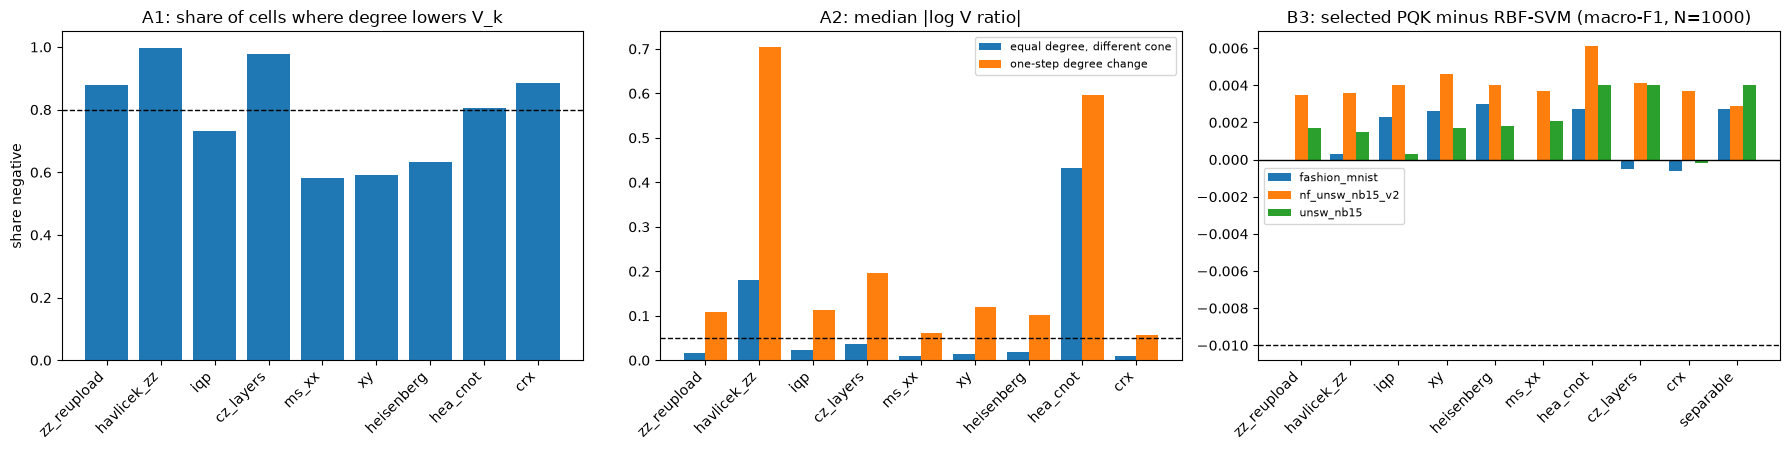

CHECKPOINT 8: figure saved -> /Users/aakarshetar/Documents/Q-kernel/Phase 0/pqk-nids/results/stage4/run/stage4_figure.png


In [16]:
try:
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(1, 3, figsize=(18, 4.6))
    x = np.arange(len(ENT))
    ax[0].bar(x, A1F.set_index("family").reindex(ENT).share_negative, color="tab:blue"); ax[0].axhline(0.8, color="k", ls="--", lw=1)
    ax[0].set_xticks(x); ax[0].set_xticklabels(ENT, rotation=45, ha="right"); ax[0].set_ylim(0, 1.05)
    ax[0].set_title("A1: share of cells where degree lowers V_k"); ax[0].set_ylabel("share negative")
    a2p = A2F.set_index("family").reindex(ENT)
    ax[1].bar(x - 0.2, a2p.median_equal_degree, 0.4, label="equal degree, different cone"); ax[1].bar(x + 0.2, a2p.median_one_step_degree, 0.4, label="one-step degree change")
    ax[1].axhline(0.05, color="k", ls="--", lw=1); ax[1].set_xticks(x); ax[1].set_xticklabels(ENT, rotation=45, ha="right")
    ax[1].set_title("A2: median |log V ratio|"); ax[1].legend(fontsize=8)
    tasks = list(TASKS); w = 0.8 / len(tasks); xf = np.arange(len(FAMS))
    for i, t in enumerate(tasks):
        s = B3r[(B3r.task == t) & (B3r.N == nprim)].set_index("family").reindex(FAMS)
        ax[2].bar(xf + (i - (len(tasks) - 1) / 2) * w, s.pqk_macro_f1 - s.comparator_macro_f1, w, label=t.split(":")[0])
    ax[2].axhline(0, color="k", lw=1); ax[2].axhline(-0.01, color="k", ls="--", lw=1)
    ax[2].set_xticks(xf); ax[2].set_xticklabels(FAMS, rotation=45, ha="right"); ax[2].legend(fontsize=8)
    ax[2].set_title(f"B3: selected PQK minus RBF-SVM (macro-F1, N={nprim})")
    plt.tight_layout(); plt.savefig(RES / "stage4_figure.png", dpi=160); plt.show()
except ImportError:
    print("matplotlib not installed: figure skipped")
print("CHECKPOINT 8: figure saved ->", RES / "stage4_figure.png")

## What to send back
* After **smoke**: `pqk-nids/results/stage4/smoke/` (zipped) and this notebook with its outputs.
* After **Part A** of the run (checkpoint 5 printed): `pqk-nids/results/stage4/run/partA/` (zipped). Part B can keep running.
* After the **full run**: the whole folder `pqk-nids/results/stage4/run/` (zipped), this executed notebook and `pqk-nids/stage4_freeze/`.